# Fixed-area cycles: registered confirmation

## Question and why it matters
Does the extreme interior-excursion tail predict boundary activity when visited
area is fixed by design? Does it add held-out information beyond boundary
residence and perimeter/area? See [registration and results](README.md),
[lab notebook](NOTEBOOK.md), and [research context](../../../notes/cutoff-research-avenues-2026-10-15.md).

## Assumptions and definitions
The selected 44-rule T1b cohort is not representative of all chaotic rules.
Patched starts use radius 2. State t follows t moves; B means the current visited
cell has an unvisited four-neighbour. Bands contain departures between first
hits of the registered areas. Boundary labels change with the visited region.
Quantiles pool complete-contained I episodes across 16 seeds; kappa_time is
boundary fraction divided by time-averaged P/A. Seed groups A/B predict C/D
in the primary test. Reliability is checked rather than assumed.

## Provenance
All inputs below are small files under results/. No dumps are read. Files are currently uncommitted; commit only on user request.

In [1]:
from pathlib import Path
import csv, datetime, hashlib, json, subprocess
SEED = 20261016
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'Cargo.toml').exists() and (p / 'experiments').is_dir())
EXP = ROOT / 'experiments/archive/2026-10-fixed-area-cycles'
names = ['analysis.json', 'rule_summary.csv', 'audit.json', 'determinism.json',
         'cohort_rules.txt', 'controls_summary.csv', 'controls.txt', 'pilot_feasibility.txt',
         'association.png', 'association.json']
print('git', subprocess.check_output(['git', 'rev-parse', 'HEAD'], cwd=ROOT, text=True).strip())
print('UTC', datetime.datetime.now(datetime.timezone.utc).isoformat(), 'bootstrap seed', SEED)
for name in names:
    p = EXP / 'results' / name
    print(p.relative_to(ROOT), hashlib.sha256(p.read_bytes()).hexdigest())
analysis = json.loads((EXP / 'results/analysis.json').read_text())
audit = json.loads((EXP / 'results/audit.json').read_text())
det = json.loads((EXP / 'results/determinism.json').read_text())
assert analysis['bootstrap']['seed'] == SEED
print('Frozen config SHA256:', analysis['config_sha256'])

git 275c2afe3e03b9d08600447acf0840e5ca3d9543
UTC 2026-10-15T09:28:26.040963+00:00 bootstrap seed 20261016
experiments/2026-10-15-fixed-area-cycles/results/analysis.json 626e340256f4dcd09b39d8e7de1c39199a80423205d73fa0e6ae04d7a81a9545
experiments/2026-10-15-fixed-area-cycles/results/rule_summary.csv c10ec29f914bae0f0d32c18c1ad3a871a8407494d032705931a1c84eaf1893c6
experiments/2026-10-15-fixed-area-cycles/results/audit.json 4f0672566ce779cbc569bd11b45e9a6a6c3f32f301e92333e5c8fe51e400c520
experiments/2026-10-15-fixed-area-cycles/results/determinism.json 38dec55622a1b7d27c07a48bd42f015d96991760e3533afac4782b6dd99977cc
experiments/2026-10-15-fixed-area-cycles/results/cohort_rules.txt 91cde6e93f8a0ee13b0225b5be24c5d464696cf06b1ce3471da85f657ccfe080
experiments/2026-10-15-fixed-area-cycles/results/controls_summary.csv e31b2f0a9c22211efa1206d025e726a79022c593ba300881d43d7a0f701a8393
experiments/2026-10-15-fixed-area-cycles/results/controls.txt 88be379794593dce76bbbfb08ca7ac06b429f0e9967c08dc1b1

## Data and method
Production uses 44 rules × 64 seeds (1001–1064), split into four groups of 16.
Primary bands are [32768,34816) and [131072,139264); 1/8-width bands reuse the
same seeds as a sensitivity analysis. Grid 8192, cap 2^29. The sampler,
`scripts/audit.py`, and `scripts/analyse.py` do the heavy work.
P1 averages two independent-seed Spearman correlations. P2 compares OLS with
and without ln q999 in leave-one-rule-out prediction of ln kappa; its baseline
uses ln mean B duration and ln P/A from disjoint seeds. Bootstrap uses 2000 rule
resamples; P2 resamples fixed per-rule held-out errors rather than refitting.
Both area bands must pass each prediction's threshold.

## Results
Coverage and accounting first; no failed run or rule is dropped.

In [2]:
for run in ['prod16', 'prod8']:
    print(run, audit['runs'][run])
    print('quantile minimum pooled counts:', analysis[run]['g_quantile_min_pooled_n'])
    print('max final time:', analysis[run]['checks']['max_t_final'],
          'budget gate:', analysis[run]['checks']['g_budget_ok'])
print('Determinism check:', det['scope'])
print(det['runs'])

prod16 {'specs': 2816, 'band_rows': 5632, 'not_complete': 0, 'max_censor_gate_ratio': 0.0, 'accounting_pass': True}
quantile minimum pooled counts: {'0': 16469, '1': 65701}
max final time: 78900629 budget gate: True
prod8 {'specs': 2816, 'band_rows': 5632, 'not_complete': 0, 'max_censor_gate_ratio': 0.0, 'accounting_pass': True}
quantile minimum pooled counts: {'0': 33089, '1': 131429}
max final time: 86613887 budget gate: True
Determinism check: all rules, one of 64 production seeds, both widths; full P3 determinism not established
{'prod16': {'specs': 44, 'files_compared': 220, 'byte_identical': True}, 'prod8': {'specs': 44, 'files_compared': 220, 'byte_identical': True}}


These checks test coverage and conservation. Accounting identities do not establish an excursion mechanism, and the production thread replay covers one seed per rule.

In [3]:
for run in ['prod16', 'prod8']:
    print('\n', run)
    for band in [0, 1]:
        b = analysis[run][f'band{band}']
        p1, p2 = b['P1'], b['P2']
        print(f"band {band}: reliability q={b['rel_lnq999_AB']:.3f}, kappa={b['rel_lnk_CD']:.3f}, gate={b['g_reliab_ok']}")
        print(f"  P1 rho={p1['statistic']:.3f}, CI={p1['ci95']}, numerical threshold={p1['success']}")
        print(f"  P2 R2 gain={p2['gain']:.3f}, CI={p2['ci95']}, numerical threshold={p2['success']}")
        print('  baseline/full R2 per rotation:', p2['r2_cv_baseline_full_per_rotation'])
    print('Statistically testable:', analysis[run]['statistically_testable'])
    print('P1 both bands:', analysis[run]['P1_overall_success'],
          'P2 both bands:', analysis[run]['P2_overall_success'])


 prod16
band 0: reliability q=0.613, kappa=0.964, gate=True
  P1 rho=-0.285, CI=[-0.5580743151930041, -0.004579078035367537], numerical threshold=False
  P2 R2 gain=0.336, CI=[0.11475547300502399, 0.5776163871633982], numerical threshold=True
  baseline/full R2 per rotation: [[0.19695775449239095, 0.5141782068381782], [0.1300927680721563, 0.4856277179806908]]
band 1: reliability q=0.969, kappa=0.954, gate=True
  P1 rho=-0.814, CI=[-0.9080666397755567, -0.6648269669253876], numerical threshold=True
  P2 R2 gain=0.544, CI=[0.3156555142643549, 0.8222697153849527], numerical threshold=True
  baseline/full R2 per rotation: [[0.152416716023283, 0.6835803895439244], [0.16223665092531248, 0.7199264547870816]]
Statistically testable: True
P1 both bands: False P2 both bands: True

 prod8
band 0: reliability q=0.756, kappa=0.969, gate=True
  P1 rho=-0.417, CI=[-0.6513004049839268, -0.13161206467285874], numerical threshold=True
  P2 R2 gain=0.488, CI=[0.21920720107985625, 0.766664785985314], num

The registered tests assess an association and incremental prediction in this cohort. Even a pass would not demonstrate causality; a failed reliability gate makes the predictions untestable at the achieved precision.

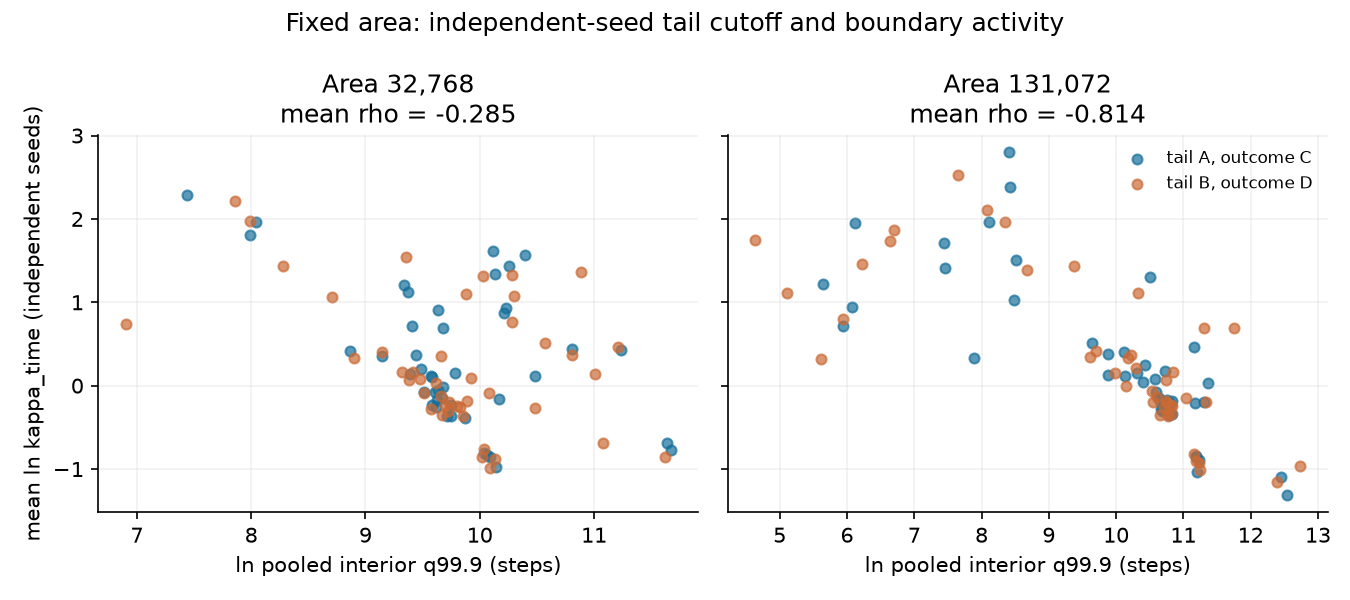

In [4]:
from IPython.display import Image, display
display(Image(filename=str(EXP / 'results/association.png')))

Each panel shows 44 rules twice, using disjoint seed rotations; the dots are not 88 independent rules. The plot shows the registered association and does not control field geometry or demonstrate tail causality.

The primary both-band verdict is P1 **FAIL**
and secondary P2 **PASS**.
P1 correlations are -0.285 and
-0.814; its required cutoff is <= -0.30 at both
bands. P2 held-out R2 gains are 0.336 and
0.544. The smaller-area primary association cannot
be rescued by rounding or reporting only the sign of its confidence interval.
The q999 predictor adds information in the registered model; it does not measure
the amount of time carried by the tail or establish mediation.

The 1/8-width sensitivity passes P1 at both areas (-0.417 and -0.815) and
passes P2 again. It reuses the same seeds and does not rescue the primary P1
failure. The smaller-area conclusion depends on band width; the wider band
changes both event counts and the sampling ensemble.

## Between-seed uncertainty
Per-rule `lnk_time_sd` is the sample sd across 16 seeds. The following quantities compare variation across the four groups with variation across rule means.

In [5]:
for band in [0, 1]:
    b = analysis['prod16'][f'band{band}']
    for col in ['ln_q999', 'lnk_time']:
        print('band', band, col, 'between-rule sd', b[f'{col}_sd_between_rules_of_means'],
              'RMS within-rule group sd', b[f'{col}_mean_within_rule_group_sd'])

band 0 ln_q999 between-rule sd 0.7641894927558179 RMS within-rule group sd 0.41874502626506516
band 0 lnk_time between-rule sd 0.7821085811791467 RMS within-rule group sd 0.21759668900593318
band 1 ln_q999 between-rule sd 1.7948212916216748 RMS within-rule group sd 0.34518263826742795
band 1 lnk_time between-rule sd 0.9263405951894846 RMS within-rule group sd 0.18628554812245166


These dispersion estimates expose finite-seed noise. Group dispersion is not the standard error of a single trajectory or proof of a universal noise ceiling.

## Caveats and controls
Oracle/property tests and the release suite validate instrumentation. Rotor and
random-walk controls quantify band-width and normalization effects; see
`results/controls.txt`. Their conditional kappa has no prespecified known target.
The pilot budget gate initially failed; the cap was raised before production.
The all-production conservation audit and the one-seed-per-rule thread replay
are different checks: the full all-seed determinism clause of P3 remains unchecked.
First-area-hit sampling differs from fixed-time sampling. Equal area does not
fix age, shape or colour field. The width sensitivity shares trajectories.
The q999 cutoff is not a direct tail-time-burden measurement, and P2 uses ln kappa
rather than unnormalized occupancy. This limits any mechanistic interpretation.
The prior matched-area noise-floor failure remains failed.

## What this changes / next steps
Use the registered gate verdicts above to decide whether the earlier cutoff lead
survives fixed-area sampling at this precision. Do not select a successful band
or replace the tail statistic after seeing outcomes. A fresh experiment would
be needed for a revised estimand, larger cohort, or causal mutation/transplant test.

## Open questions
How much of the tail variability is seed noise versus rule structure? Does a
direct tail-time burden outperform a high quantile on fresh data? Which field
interventions can change return times while controlling boundary residence?